In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("netflix_titles.csv")
print("Netflix Datasets")
print(df)

Netflix Datasets
     show_id     type                  title         director  \
0         s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1         s2  TV Show          Blood & Water              NaN   
2         s3  TV Show              Ganglands  Julien Leclercq   
3         s4  TV Show  Jailbirds New Orleans              NaN   
4         s5  TV Show           Kota Factory              NaN   
...      ...      ...                    ...              ...   
8802   s8803    Movie                 Zodiac    David Fincher   
8803   s8804  TV Show            Zombie Dumb              NaN   
8804   s8805    Movie             Zombieland  Ruben Fleischer   
8805   s8806    Movie                   Zoom     Peter Hewitt   
8806   s8807    Movie                 Zubaan      Mozez Singh   

                                                   cast        country  \
0                                                   NaN  United States   
1     Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban..

In [4]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [6]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [7]:
# Fill missing values in text columns
columns_to_fill = ["director", "cast", "country", "rating", "duration"]

for col in columns_to_fill:
    df[col] = df[col].fillna("Not Available")

# Check missing values again
df.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      8807 non-null   str  
 4   cast          8807 non-null   str  
 5   country       8807 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8807 non-null   str  
 9   duration      8807 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [9]:
# Convert date_added into datetime format
df["date_added"] = pd.to_datetime(
    df["date_added"],
    format="mixed",
    errors="coerce"
)

# Check data type
df["date_added"].dtype

dtype('<M8[us]')

In [10]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


In [11]:
typess=df["type"].value_counts()
print(typess)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


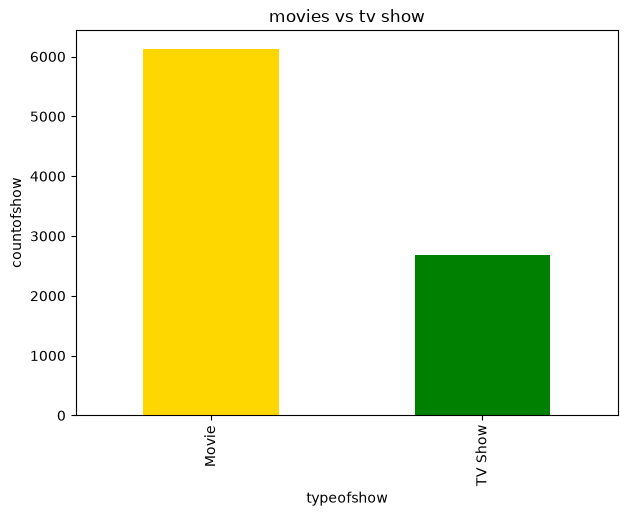

In [12]:
plt.figure(figsize=(7,5))
typess.plot(kind="bar",color=["gold","green"])
#plt.bar(typess.index , typess.values ,color=["gold","green"])
plt.title("movies vs tv show")
plt.xlabel("typeofshow")
plt.ylabel("countofshow")
plt.show()

In [13]:
year_count=df["release_year"].value_counts().sort_index()
year_count.tail(10)

release_year
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64

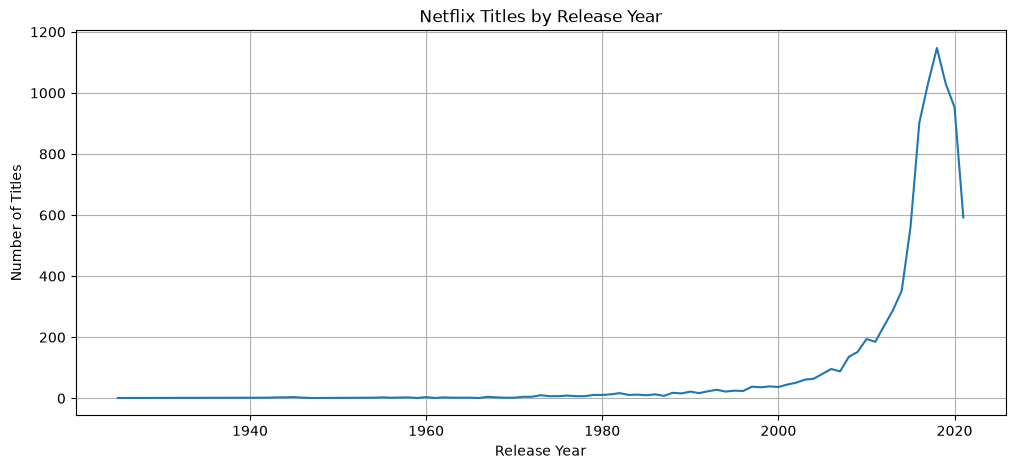

In [14]:
plt.figure(figsize=(12, 5))

#year_count.plot(kind="line")
plt.plot(year_count.index,year_count.values)
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()

In [15]:
year_type_counts = (
    df.groupby(["release_year", "type"])
      .size()
      .unstack(fill_value=0)
)

year_type_counts.tail(10)

type,Movie,TV Show
release_year,,
2012,173,64
2013,225,63
2014,264,88
2015,398,162
2016,658,244
2017,767,265
2018,767,380
2019,633,397
2020,517,436


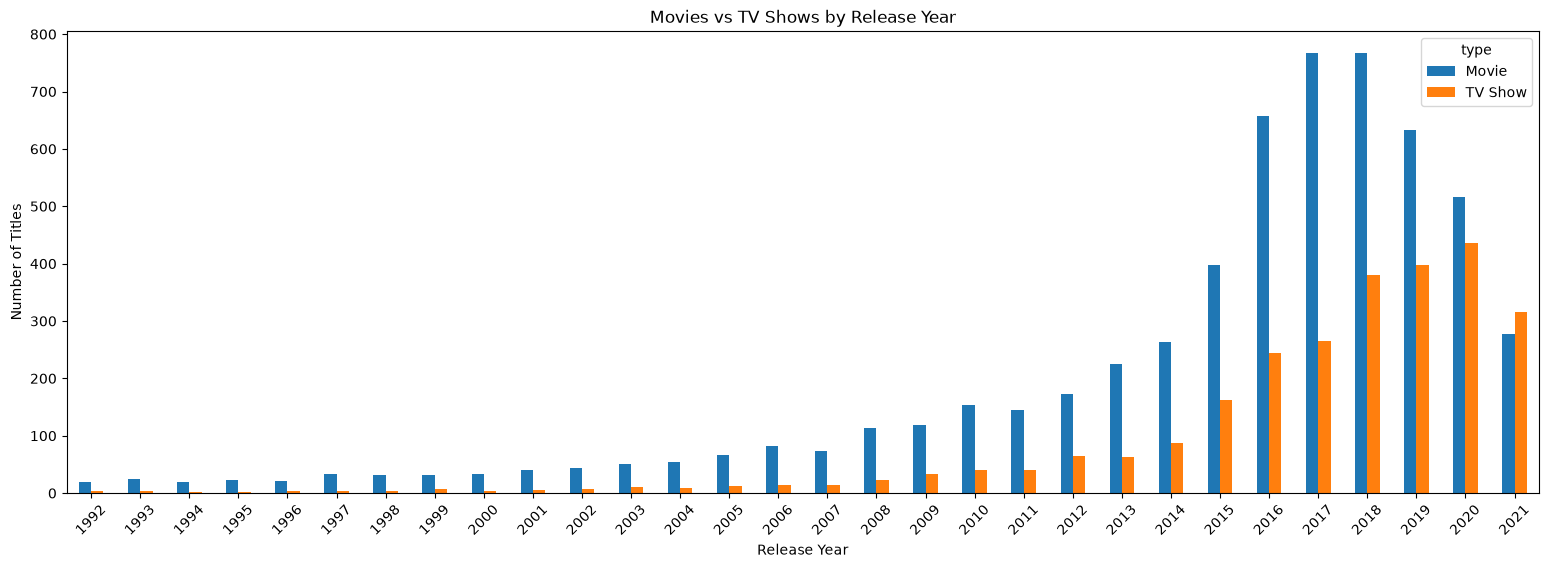

In [16]:
year_type_counts.tail(30).plot(
    kind="bar",
    figsize=(19, 6)
)

plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

In [17]:
rating=df["rating"].value_counts()
ratinghead=rating.head(7)
print(ratinghead)

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
Name: count, dtype: int64


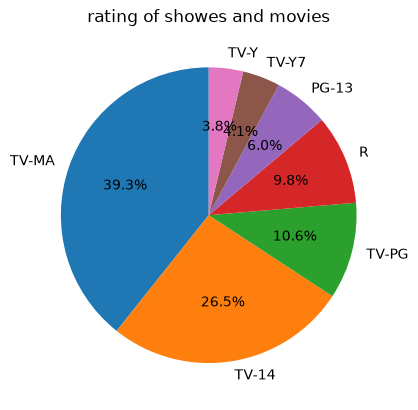

In [18]:
plt.pie(ratinghead,labels=ratinghead.index,autopct='%1.1f%%',startangle=90)
plt.title("rating of showes and movies")
plt.show()

In [19]:
df["added_year"]=df["date_added"].dt.year
df["added_year"].value_counts().sort_index()

added_year
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64

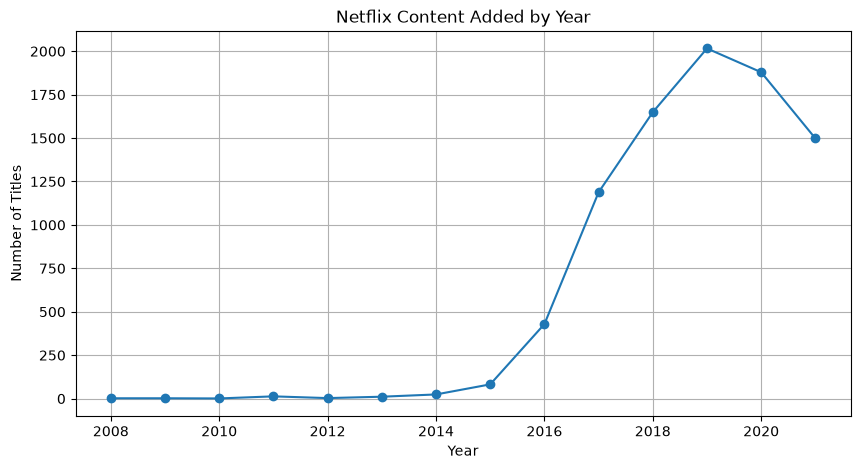

In [20]:
added_year_counts = df["added_year"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(added_year_counts.index, added_year_counts.values, marker="o")

plt.title("Netflix Content Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.grid(True)

plt.show()

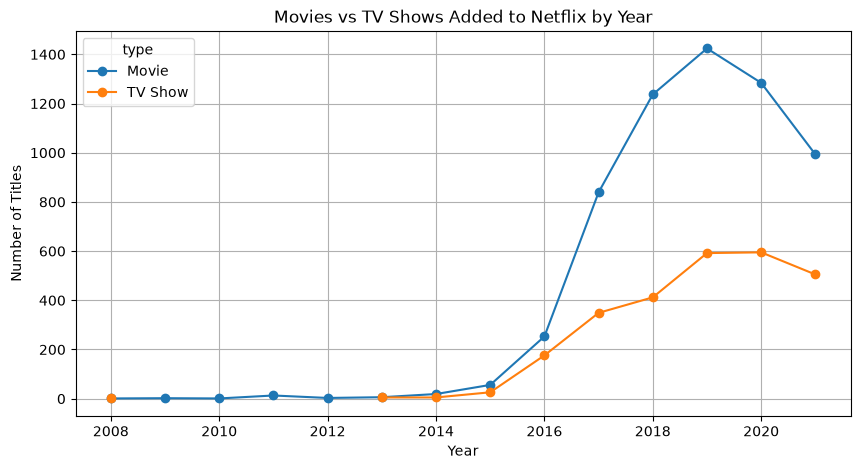

In [21]:
added_by_type = df.groupby(["added_year", "type"]).size().unstack()

added_by_type.plot(
    kind="line",
    figsize=(10, 5),
    marker="o"
)

plt.title("Movies vs TV Shows Added to Netflix by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.grid(True)

plt.show()

In [22]:
rating_counts = df["rating"].value_counts()

rating_counts

rating
TV-MA            3207
TV-14            2160
TV-PG             863
R                 799
PG-13             490
TV-Y7             334
TV-Y              307
PG                287
TV-G              220
NR                 80
G                  41
TV-Y7-FV            6
Not Available       4
NC-17               3
UR                  3
74 min              1
84 min              1
66 min              1
Name: count, dtype: int64

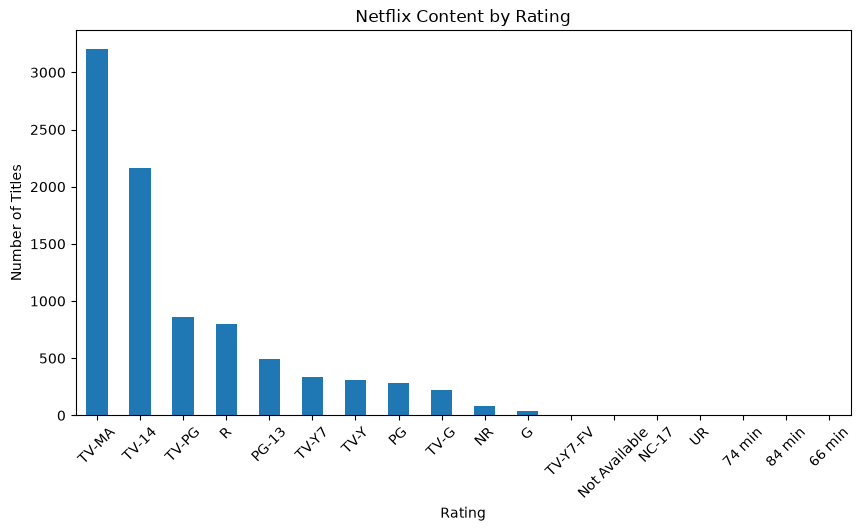

In [23]:
plt.figure(figsize=(10, 5))

rating_counts.plot(kind="bar")

plt.title("Netflix Content by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

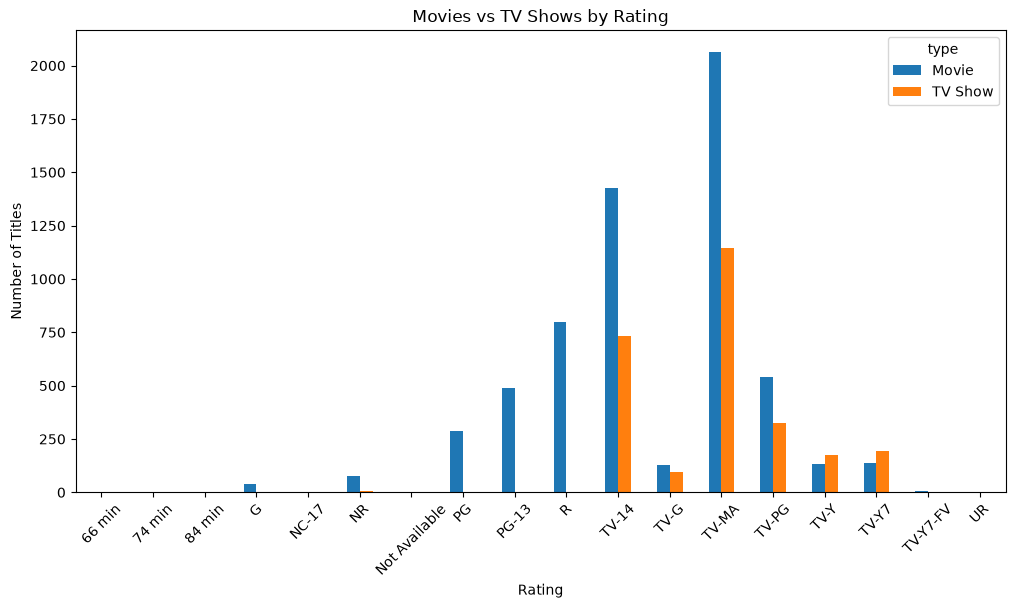

In [24]:

rating_by_type = df.groupby(["rating", "type"]).size().unstack(fill_value=0)

rating_by_type
rating_by_type.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Movies vs TV Shows by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

In [25]:
country_df=df["country"].str.split(", ").explode()
country_count=country_df.value_counts()
country_count.head(15)

country
United States     3689
India             1046
Not Available      831
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
China              162
Australia          160
Egypt              117
Turkey             113
Name: count, dtype: int64

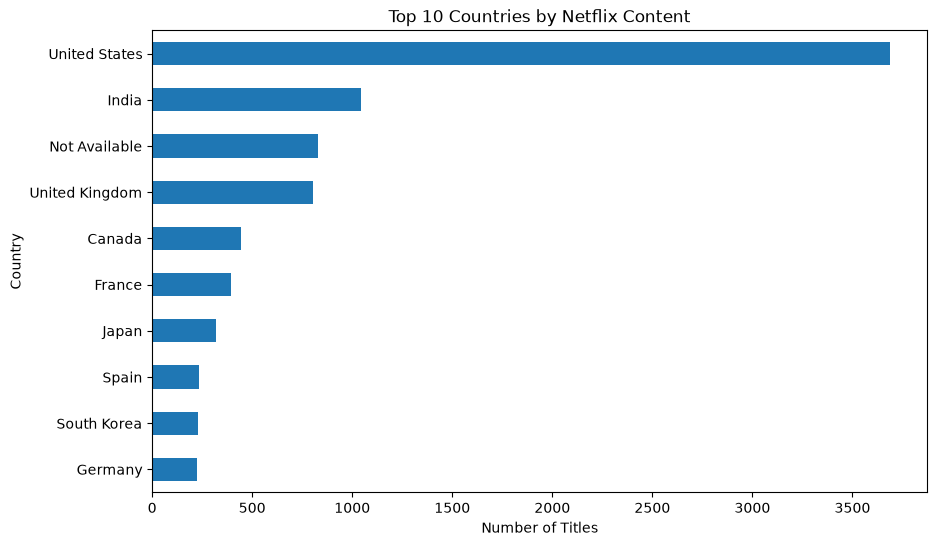

In [26]:
top_countries = country_count.head(10)

plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.show()

In [27]:
country_type_df = df.assign(
    country=df["country"].str.split(", ")
).explode("country")

country_type_counts = (
    country_type_df.groupby(["country", "type"])
    .size()
    .unstack(fill_value=0)
)

top_country_names = country_count.head(10).index

country_type_counts.loc[top_country_names]

type,Movie,TV Show
country,,
United States,2751,938
India,962,84
Not Available,440,391
United Kingdom,532,272
Canada,319,126
France,303,90
Japan,119,199
Spain,171,61
South Korea,61,170


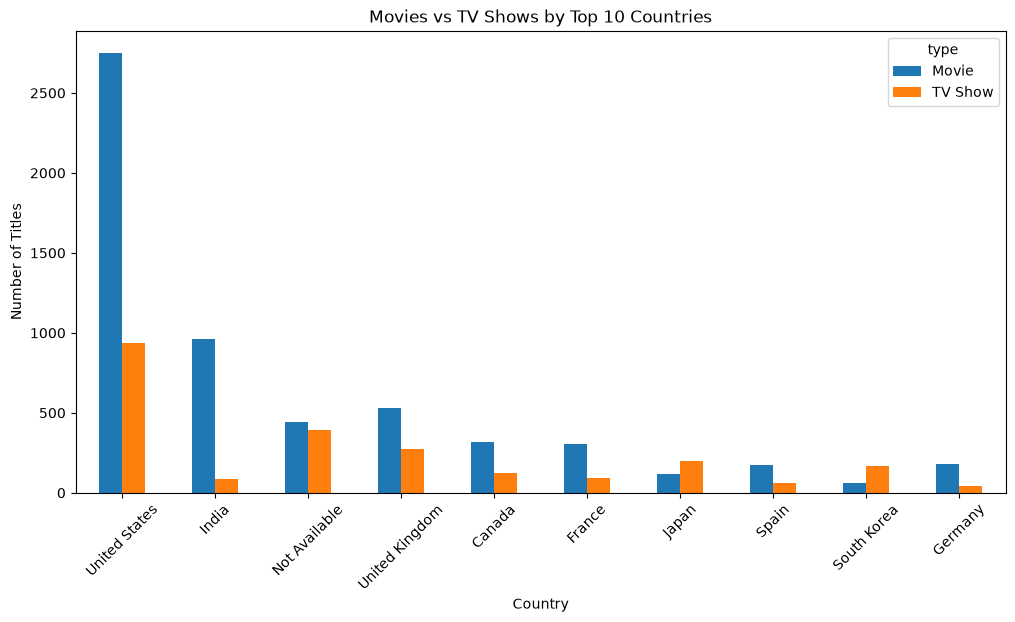

In [28]:
country_type_counts.loc[top_country_names].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Movies vs TV Shows by Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

In [29]:
genre_df = df["listed_in"].str.split(", ").explode()

genre_counts = genre_df.value_counts()

genre_counts.head(15)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
TV Comedies                  581
Thrillers                    577
Crime TV Shows               470
Kids' TV                     451
Docuseries                   395
Name: count, dtype: int64

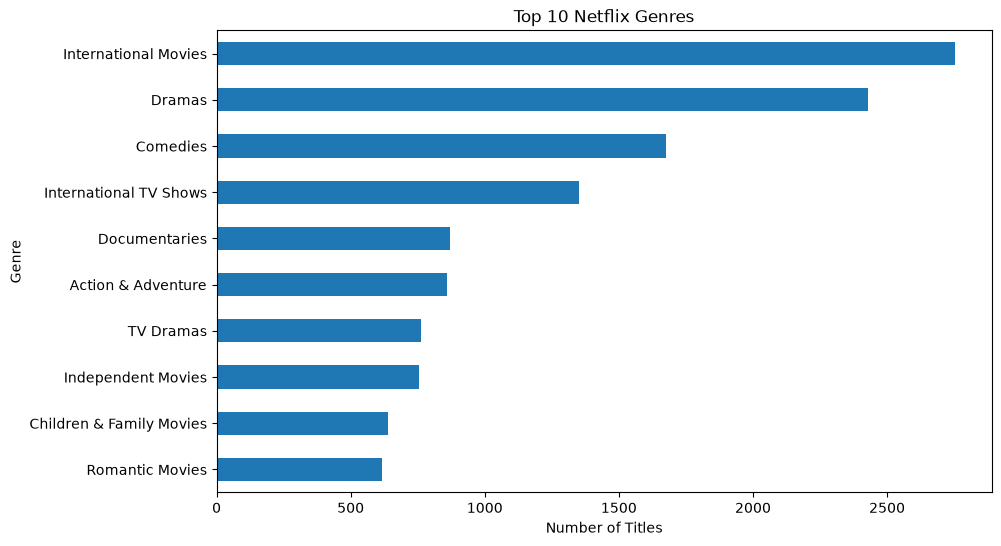

In [30]:
top_genres = genre_counts.head(10)

plt.figure(figsize=(10, 6))

top_genres.sort_values().plot(kind="barh")

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

In [31]:
genre_type_df = df.assign(
    genre=df["listed_in"].str.split(", ")
).explode("genre")

genre_type_counts = (
    genre_type_df.groupby(["genre", "type"])
    .size()
    .unstack(fill_value=0)
)

top_genre_names = genre_counts.head(10).index

genre_type_counts.loc[top_genre_names]

type,Movie,TV Show
listed_in,,
International Movies,2752,0
Dramas,2427,0
Comedies,1674,0
International TV Shows,0,1351
Documentaries,869,0
Action & Adventure,859,0
TV Dramas,0,763
Independent Movies,756,0
Children & Family Movies,641,0


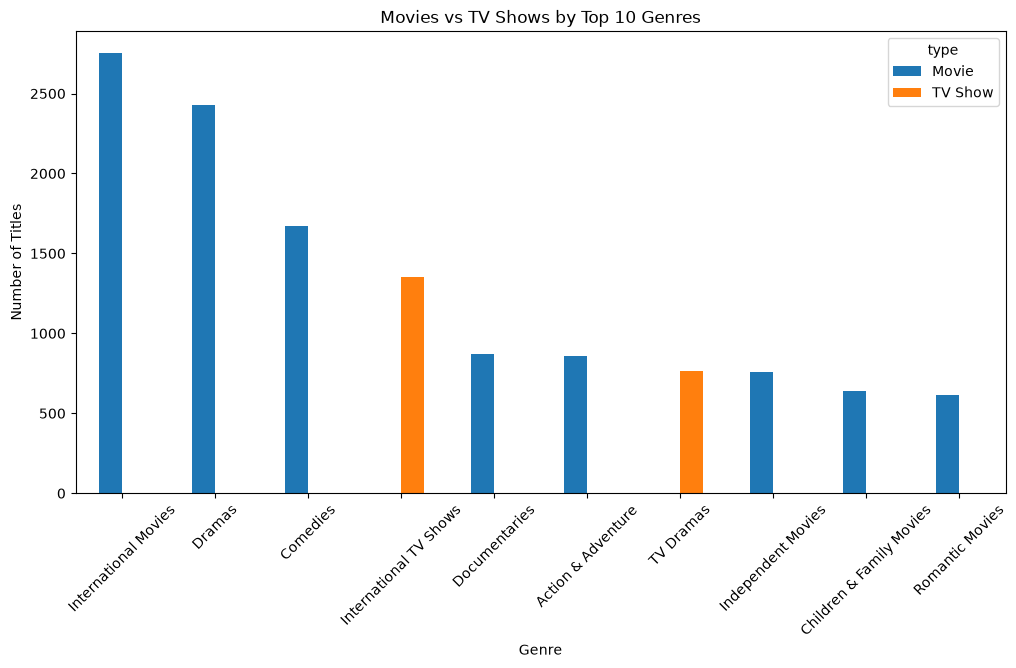

In [32]:
genre_type_counts.loc[top_genre_names].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Movies vs TV Shows by Top 10 Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

In [33]:
df[["type", "title", "duration"]].head(20)


,type,title,duration
0,Movie,Dick Johnson Is Dead,90 min
1,TV Show,Blood & Water,2 Seasons
2,TV Show,Ganglands,1 Season
3,TV Show,Jailbirds New Orleans,1 Season
4,TV Show,Kota Factory,2 Seasons
5,TV Show,Midnight Mass,1 Season
6,Movie,My Little Pony: A New Generation,91 min
7,Movie,Sankofa,125 min
8,TV Show,The Great British Baking Show,9 Seasons
9,Movie,The Starling,104 min


In [34]:
movie_duration = df.loc[
    df["type"] == "Movie", "duration"
]

movie_minutes = (
    movie_duration
    .str.extract(r"(\d+)", expand=False)
    .astype(float)
)

movie_minutes.head(10)

0      90.0
6      91.0
7     125.0
9     104.0
12    127.0
13     91.0
16     67.0
18     94.0
22    161.0
23     61.0
Name: duration, dtype: float64

In [35]:
movie_minutes.describe()

count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration, dtype: float64

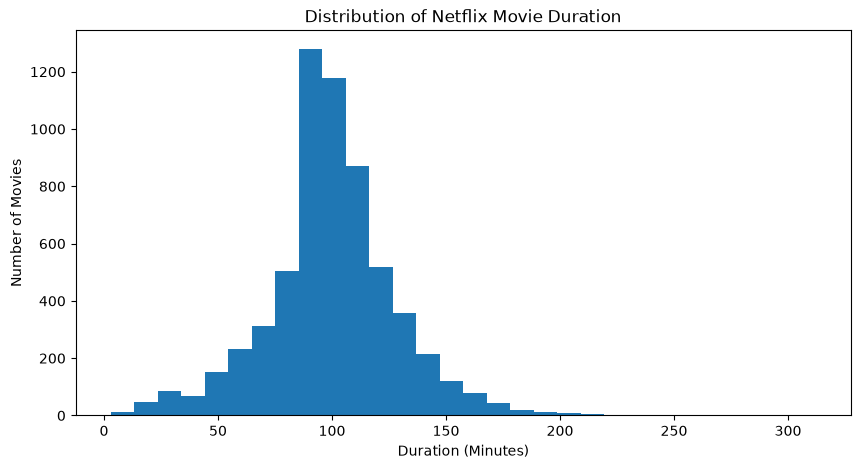

In [36]:
plt.figure(figsize=(10, 5))

plt.hist(movie_minutes.dropna(), bins=30)

plt.title("Distribution of Netflix Movie Duration")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")

plt.show()

In [37]:
tv_duration = df.loc[
    df["type"] == "TV Show", "duration"
]

tv_seasons = (
    tv_duration
    .str.extract(r"(\d+)", expand=False)
    .astype(float)
)

tv_seasons.head(10)

1     2.0
2     1.0
3     1.0
4     2.0
5     1.0
8     9.0
10    1.0
11    1.0
14    1.0
15    4.0
Name: duration, dtype: float64

In [38]:
tv_seasons.describe()

count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration, dtype: float64

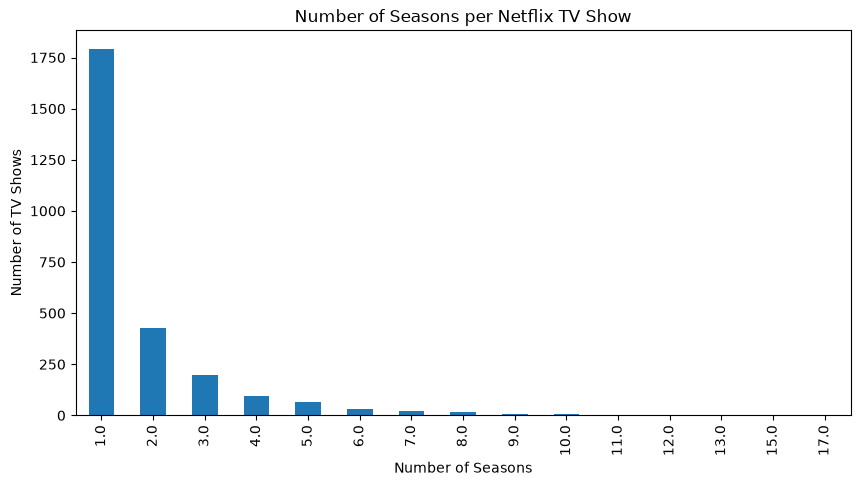

In [39]:
plt.figure(figsize=(10, 5))

tv_seasons.dropna().value_counts().sort_index().plot(kind="bar")

plt.title("Number of Seasons per Netflix TV Show")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")

plt.show()

In [40]:
director_df=df["director"].str.split(", ").explode()
director_count=director_df[director_df!="Not Available"].value_counts()
director_count.head(15)

director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Suhas Kadav            16
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Youssef Chahine        12
Martin Scorsese        12
Jay Chapman            12
Steven Spielberg       11
Don Michael Paul       10
David Dhawan            9
Yılmaz Erdoğan          9
Anurag Kashyap          9
Name: count, dtype: int64

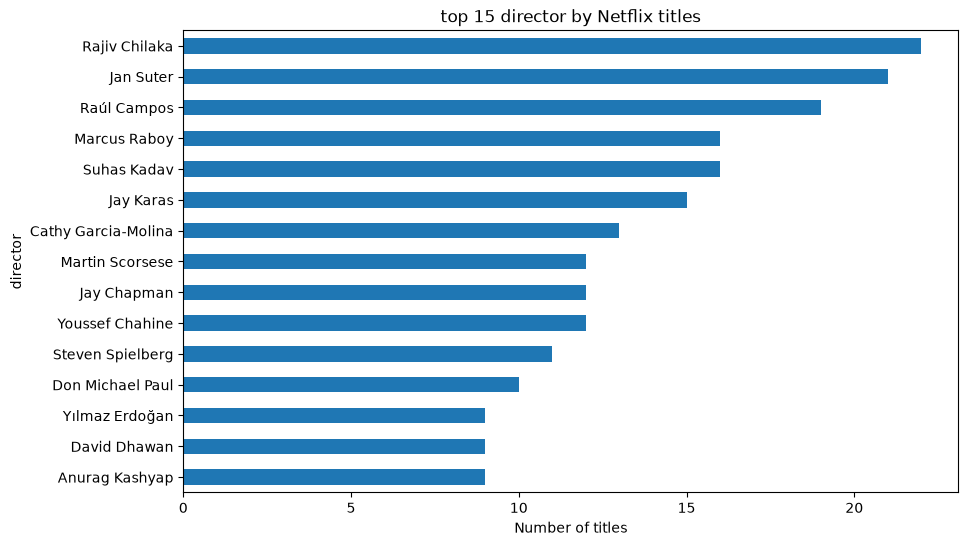

In [41]:
top_directors=director_count.head(15)
plt.figure(figsize=(10,6))
top_directors.sort_values().plot(kind="barh")
plt.title("top 15 director by Netflix titles")
plt.xlabel("Number of titles")
plt.ylabel("director")

plt.show()

In [42]:
cast_df = df["cast"].str.split(", ").explode()

cast_counts = (
    cast_df[cast_df != "Not Available"]
    .value_counts()
)

cast_counts.head(15)

cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Naseeruddin Shah    32
Takahiro Sakurai    32
Rupa Bhimani        31
Akshay Kumar        30
Om Puri             30
Yuki Kaji           29
Amitabh Bachchan    28
Paresh Rawal        28
Boman Irani         27
Rajesh Kava         26
Vincent Tong        26
Andrea Libman       25
Name: count, dtype: int64

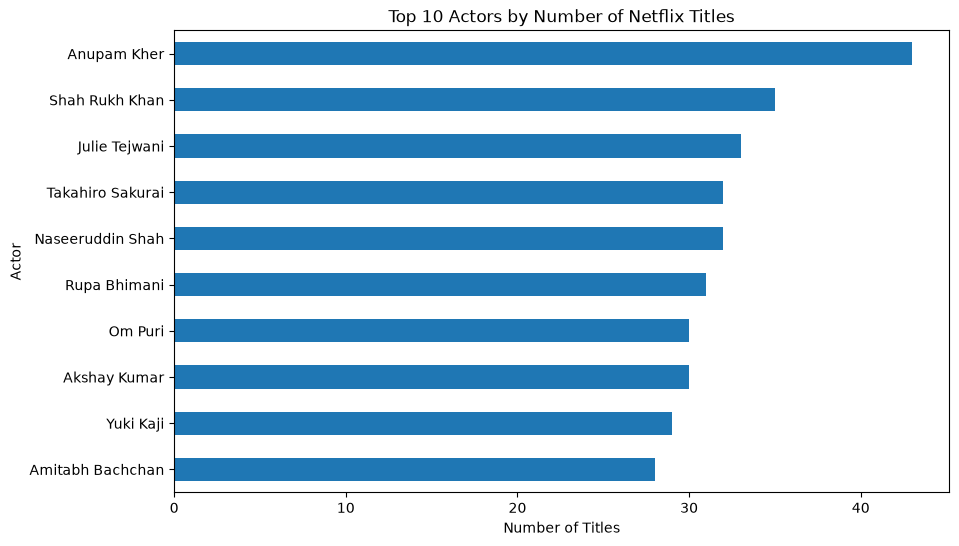

In [43]:
top_actors = cast_counts.head(10)

plt.figure(figsize=(10, 6))

top_actors.sort_values().plot(kind="barh")

plt.title("Top 10 Actors by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Actor")

plt.show()

In [44]:
cast_type_df = df.assign(
    actor=df["cast"].str.split(", ")
).explode("actor")

cast_type_counts = (
    cast_type_df[
        cast_type_df["actor"] != "Not Available"
    ]
    .groupby(["actor", "type"])
    .size()
    .unstack(fill_value=0)
)

top_actor_names = cast_counts.head(10).index

cast_type_counts.loc[top_actor_names]

type,Movie,TV Show
cast,,
Anupam Kher,42,1
Shah Rukh Khan,35,0
Julie Tejwani,28,5
Naseeruddin Shah,32,0
Takahiro Sakurai,7,25
Rupa Bhimani,27,4
Akshay Kumar,30,0
Om Puri,30,0
Yuki Kaji,10,19


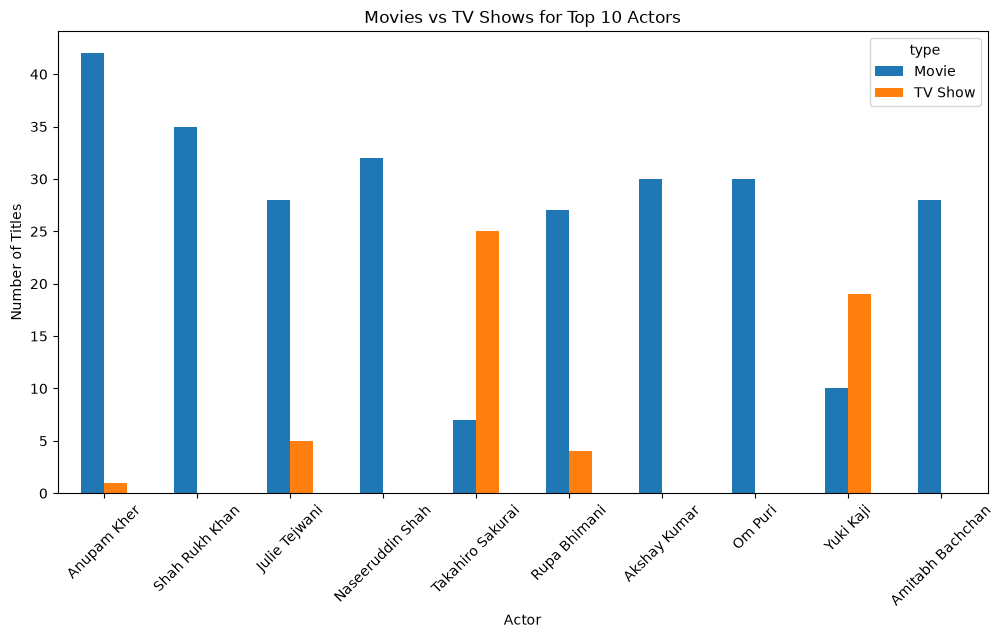

In [45]:
cast_type_counts.loc[top_actor_names].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Movies vs TV Shows for Top 10 Actors")
plt.xlabel("Actor")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

In [51]:
year_type = (
    df.groupby(["release_year", "type"])
    .size()
    .unstack(fill_value=0)
)

year_type.tail(20)


type,Movie,TV Show
release_year,,
2002,44,7
2003,51,10
2004,55,9
2005,67,13
2006,82,14
2007,74,14
2008,113,23
2009,118,34
2010,154,40


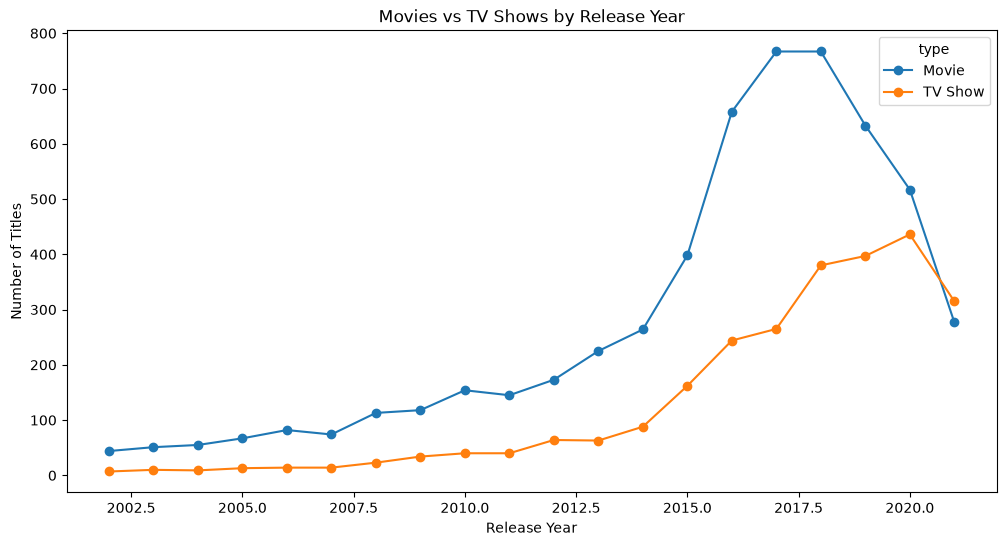

In [52]:
year_type.tail(20).plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

In [56]:
total_titles = len(df)
total_movies = (df["type"] == "Movie").sum()
total_tv_shows = (df["type"] == "TV Show").sum()
total_countries = country_count.shape[0]
total_genres = genre_counts.shape[0]

print("Total Titles:", total_titles)
print("Total Movies:", total_movies)
print("Total TV Shows:", total_tv_shows)
print("Total Countries:", total_countries)
print("Total Genres:", total_genres)

Total Titles: 8807
Total Movies: 6131
Total TV Shows: 2676
Total Countries: 128
Total Genres: 42


In [60]:
top_genres = genre_counts.head(10)

print("Top 10 Genres:")
print(top_genres)

Top 10 Genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


In [62]:
top_countries = country_count.head(10)

print("Top 10 Countries:")
print(top_countries)

Top 10 Countries:
country
United States     3689
India             1046
Not Available      831
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


In [64]:
top_directors = director_count.head(10)

print("Top 10 Directors:")
print(top_directors)

Top 10 Directors:
director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Suhas Kadav            16
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Youssef Chahine        12
Martin Scorsese        12
Jay Chapman            12
Name: count, dtype: int64


In [65]:
top_actors = cast_counts.head(10)

print("Top 10 Actors:")
print(top_actors)

Top 10 Actors:
cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Naseeruddin Shah    32
Takahiro Sakurai    32
Rupa Bhimani        31
Akshay Kumar        30
Om Puri             30
Yuki Kaji           29
Amitabh Bachchan    28
Name: count, dtype: int64


In [66]:
df.to_csv("netflix_cleaned.csv", index=False)

print("File saved successfully!")

File saved successfully!


In [67]:
import os

print(os.path.abspath("netflix_cleaned.csv"))

C:\Users\Krishna Yadav\Downloads\archive\netflix_cleaned.csv
